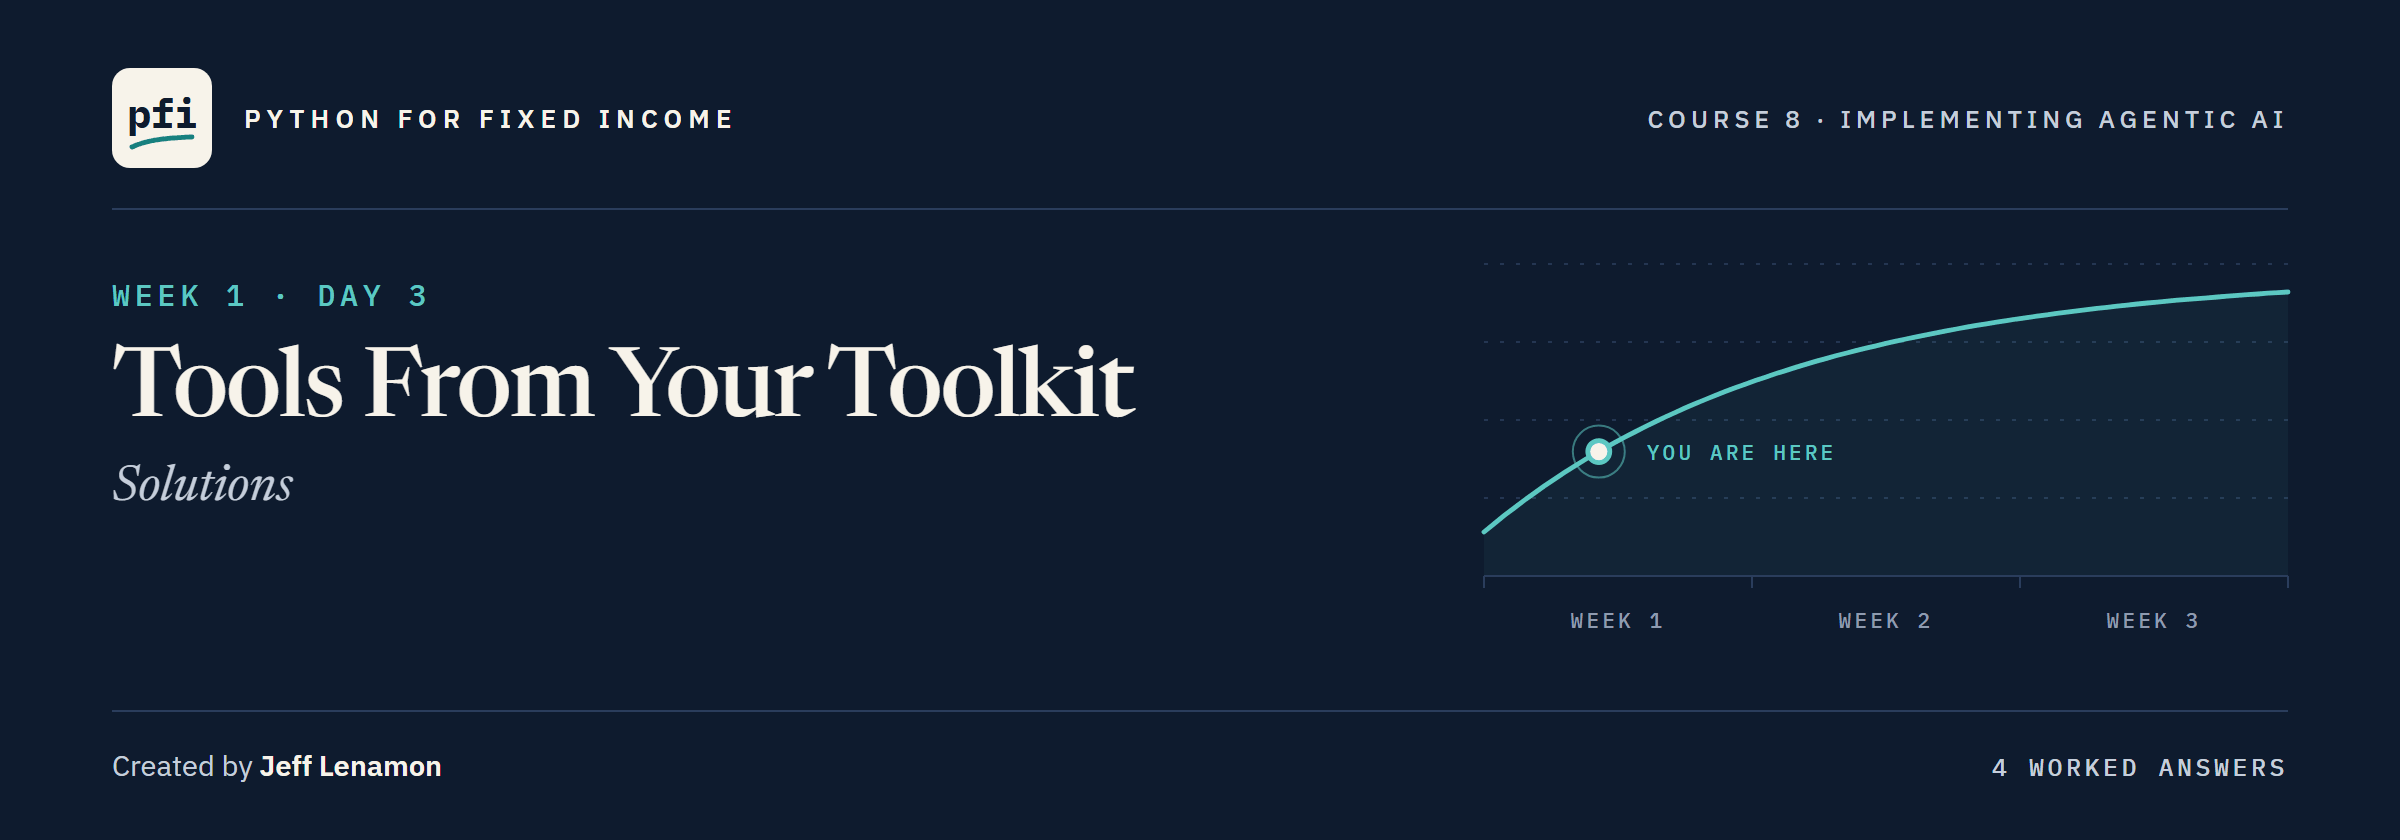

# Tools From Your Toolkit: Solutions

Week 1, Day 3. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day3/03_tools_from_your_toolkit_solutions.ipynb)

# Setting Up

## Course Setup

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# a function's signature and docstring read from Python itself (inspect), text as JSON, patterns, and dates
import inspect
import json
import re
from datetime import date

# to load and work with the data
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## The Model, Live or Replayed

In [3]:
# the model: with your own key each request goes to the model; without one, the course's saved runs answer it
import hashlib
import json
import sys

# Colab does not come with these: this installs them there (on your machine, requirements.txt already did)
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install --quiet openai==3.26.0 python-dotenv==1.2.4")

import httpx2
from dotenv import dotenv_values
from openai import OpenAI

# today's saved runs: one file for each request the course sent, named by the request's fingerprint
RUNS = DATA + "course8_agent_runs/day03/"
MODEL = "gpt-4.1-mini"


def fingerprint(request):
    """The SHA-256 of a request's method, path and JSON body; never its headers, which carry the key."""
    text = json.dumps({"method": request.method, "path": request.url.path, "body": json.loads(request.content)},
                      sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode()).hexdigest()


def replay(request):
    """The saved response to exactly this request."""
    saved = pd.read_json(RUNS + fingerprint(request) + ".json", typ="series")
    return httpx2.Response(200, json=saved["response"])


# your own key, if you have one: an environment variable, my_bondmath\.env (Course 3), or Colab's Secrets panel
key = os.environ.get("OPENAI_API_KEY") or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENAI_API_KEY")
if not key and "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = userdata.get("OPENAI_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None

if key:
    client = OpenAI(api_key=key)
    MODE = "live"
else:
    saved_runs = httpx2.MockTransport(replay)
    client = OpenAI(api_key="replay", http_client=httpx2.Client(transport=saved_runs))
    MODE = "replay"
print(f"Mode: {MODE}.")

Mode: replay.


## The Tools From Earlier Days

In [4]:
# Day 1's system prompt, as Day 1's saved first request carries it
day1_saved = pd.read_json(DATA + "course8_agent_runs/day01/17e1482ec8746857fa444b9bf058775eabe478af6df111aa120578eff9bd1fdd.json", typ="series")
DESK_PROMPT = day1_saved["request"]["messages"][0]["content"]

In [5]:
# one tool message for each tool request: a tool that fails goes back to the model as words, never a number
def run_tools(assistant_message, tools):
    """Run each tool request of an assistant message and return one tool message for each."""
    tool_messages = []
    for tool_request in assistant_message["tool_calls"]:
        name = tool_request["function"]["name"]
        if name not in tools:
            tool_result = {"error": f"unknown tool {name}; the tools are {list(tools)}"}
        else:
            try:
                tool_result = tools[name](**json.loads(tool_request["function"]["arguments"]))
            except (TypeError, ValueError) as error:
                tool_result = {"error": str(error)}
        tool_messages.append({"role": "tool", "tool_call_id": tool_request["id"],
                              "content": json.dumps({"tool_call_id": tool_request["id"]} | tool_result, sort_keys=True)})
    return tool_messages

In [6]:
# the loop as a function: send, act, stop, with a step limit
def agent_loop(client, question, tools, schemas, max_steps=8):
    """Run a question until a reply holds text or max_steps requests are sent, and return the run."""
    messages = [{"role": "system", "content": DESK_PROMPT}, {"role": "user", "content": question}]
    body = {"model": MODEL, "tools": schemas, "temperature": 0, "seed": SEED, "max_tokens": 300,
            "parallel_tool_calls": False}
    replies = []
    for step in range(max_steps):
        request_body = body | {"messages": messages}
        reply = client.chat.completions.create(**request_body)
        replies.append(reply)
        message = reply.choices[0].message
        if not message.tool_calls:
            answer = {"role": "assistant", "content": message.content}
            return {"messages": messages + [answer], "replies": replies, "stop": "answer"}
        sent = {"role": "assistant", "content": None, "tool_calls": [t.model_dump(exclude_none=True) for t in message.tool_calls]}
        messages = messages + [sent] + run_tools(sent, tools)
    return {"messages": messages, "replies": replies, "stop": "max_steps"}

In [7]:
# a run as a table: one row a request, what its reply held, and what it cost in tokens
def trace_table(run):
    """One row per request of a run: the finish reason, the tool request and its result, and the tokens."""
    results = [m["content"] for m in run["messages"] if m["role"] == "tool"]
    rows = []
    for step, reply in enumerate(run["replies"], start=1):
        message = reply.choices[0].message
        row = {"step": step, "finish_reason": reply.choices[0].finish_reason, "tool": "", "arguments": "",
               "result": message.content or "", "prompt_tokens": reply.usage.prompt_tokens,
               "completion_tokens": reply.usage.completion_tokens}
        if message.tool_calls:
            row = row | {"tool": message.tool_calls[0].function.name, "arguments": message.tool_calls[0].function.arguments,
                         "result": results[step - 1]}
        rows.append(row)
    return pd.DataFrame(rows)

## Today's Toolkit

In [8]:
# Course 2's 30/360 coupon period and price on any date
def coupon_period(settlement, maturity):
    """Days accrued on 30/360 since the last coupon, and the number of coupons left."""
    settle, mature = date.fromisoformat(settlement), date.fromisoformat(maturity)
    coupons_left, previous = 0, mature
    while previous > settle:
        coupons_left = coupons_left + 1
        previous = (pd.Timestamp(mature) - pd.DateOffset(months=6 * coupons_left)).date()
    days = 360 * (settle.year - previous.year) + 30 * (settle.month - previous.month) + settle.day - previous.day
    return days, coupons_left


def dirty_price(settlement, maturity, coupon_pct, yield_pct):
    """The price per 100 of face with accrued interest, semiannual coupons, 30/360."""
    days, coupons_left = coupon_period(settlement, maturity)
    w = (180 - days) / 180
    flows = [coupon_pct / 2] * (coupons_left - 1) + [coupon_pct / 2 + 100]
    return sum(flow / (1 + yield_pct / 200) ** (w + k) for k, flow in enumerate(flows))


def accrued(settlement, maturity, coupon_pct):
    """The accrued interest per 100 of face: half the coupon times the days accrued over 180."""
    return coupon_pct / 2 * coupon_period(settlement, maturity)[0] / 180

In [9]:
# the seven tools, as the teaching notebook writes them
def price(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The clean price per 100 of face of a fixed-coupon bond (semiannual coupons, 30/360), from its yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    clean = dirty_price(settlement, maturity, coupon_pct, yield_pct) - accrued(settlement, maturity, coupon_pct)
    return {"clean_price_per_100": round(clean, 6)}


def yield_to_maturity(settlement: str, maturity: str, coupon_pct: float, clean_price: float) -> dict:
    """The yield to maturity in percent of a fixed-coupon bond (semiannual coupons, 30/360), from its clean price.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        clean_price: the clean price per 100 of face, for example 99.74.
    """
    low, high = -5.0, 100.0
    while high - low > 1e-10:
        middle = (low + high) / 2
        if dirty_price(settlement, maturity, coupon_pct, middle) - accrued(settlement, maturity, coupon_pct) > clean_price:
            low = middle
        else:
            high = middle
    return {"yield_pct": round((low + high) / 2, 6)}


def accrued_interest(settlement: str, maturity: str, coupon_pct: float) -> dict:
    """The accrued interest per 100 of face the buyer pays the seller (semiannual coupons, 30/360).

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
    """
    return {"accrued_per_100": round(accrued(settlement, maturity, coupon_pct), 6)}

In [10]:
# the seven tools, continued
def modified_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The modified duration in years: the percent price change for a 100 bp change in yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    full = dirty_price(settlement, maturity, coupon_pct, yield_pct)
    return {"modified_duration_years": round((down - up) / 0.0002 / full, 6)}


def dv01(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The DV01 in price points per 100 of face: the price change for a 1 bp fall in yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    if 0 < coupon_pct < 0.5:
        return {"error": f"coupon_pct {coupon_pct} is below 0.5: write the coupon in percent, 5.0 for a 5% coupon"}
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    return {"dv01_per_100": round((down - up) / 2, 6)}


def spread_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The spread duration in years: the percent price change for a 100 bp move in the spread.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    years = modified_duration(settlement, maturity, coupon_pct, yield_pct)["modified_duration_years"]
    return {"spread_duration_years": years}


def dts(spread_duration_years: float, spread_bp: float) -> dict:
    """Duration times spread (DTS) in years times bp: spread duration in years times the spread in bp.

    Args:
        spread_duration_years: the spread duration in years, for example 4.627.
        spread_bp: the spread in basis points, for example 147.
    """
    return {"dts_years_bp": round(spread_duration_years * spread_bp, 6)}

In [11]:
# the schema read from a docstring, the toolkit, and the DTS run Exercise 3 reads
TYPES = {str: "string", float: "number"}


def tool_schema(function):
    """A tool's schema read from a function's name, signature and docstring."""
    lines = inspect.getdoc(function).splitlines()
    described = {}
    for line in lines[lines.index("Args:") + 1:]:
        name, words = line.strip().split(": ", 1)
        described[name] = words
    parameters = inspect.signature(function).parameters
    properties = {name: {"type": TYPES[p.annotation], "description": described[name]} for name, p in parameters.items()}
    return {"type": "function", "function": {
        "name": function.__name__, "description": lines[0], "strict": True,
        "parameters": {"type": "object", "properties": properties, "required": list(parameters),
                       "additionalProperties": False}}}


TOOLS = {f.__name__: f for f in (price, yield_to_maturity, accrued_interest, modified_duration, dv01, spread_duration, dts)}
SCHEMAS = [tool_schema(f) for f in TOOLS.values()]
DTS_QUESTION = ("As of 2026-09-30, what is the DTS, the spread duration in years times the spread in bp, of bond 99080CAE8 of "
                "the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp?")
run_dts = agent_loop(client, DTS_QUESTION, TOOLS, SCHEMAS)
terms = {"settlement": "2026-09-30", "maturity": "2050-02-26", "coupon_pct": 7.0, "yield_pct": 6.393}

# Wrapping Up

## Exercises

In [12]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**An Eighth Tool**

In [13]:
# the eighth tool: the sum form, each flow's t (t + 0.5) discounted two periods past its own, over the dirty price
def convexity(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The convexity in years squared of a fixed-coupon bond (semiannual coupons, 30/360), from its yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    days, coupons_left = coupon_period(settlement, maturity)
    w = (180 - days) / 180
    rate = yield_pct / 200
    flows = [coupon_pct / 2] * (coupons_left - 1) + [coupon_pct / 2 + 100]
    times = [(w + k) / 2 for k in range(len(flows))]
    bend = sum(flow * t * (t + 0.5) / (1 + rate) ** (2 * t + 2) for t, flow in zip(times, flows))
    return {"convexity_years_squared": round(bend / dirty_price(settlement, maturity, coupon_pct, yield_pct), 6)}


EX1_QUESTION = ("As of 2026-09-30, what is the convexity in years squared of bond 99033HAF2 of the synthetic holdings, "
                "a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield?")

# the eight tools: the convexity schema read from its docstring like the others
run_ex1 = agent_loop(client, EX1_QUESTION, TOOLS | {"convexity": convexity}, SCHEMAS + [tool_schema(convexity)])
table_ex1 = trace_table(run_ex1)
ex1_run = [[tool for tool in table_ex1["tool"] if tool], json.loads(table_ex1["result"][0])["convexity_years_squared"]]
print(ex1_run, "| first request:", table_ex1["prompt_tokens"][0], "prompt tokens")

[['convexity'], 206.928841] | first request: 1178 prompt tokens


In [14]:
# agent answer
print(run_ex1["replies"][-1].choices[0].message.content)

As of 2026-09-30, the convexity in years squared of bond 99033HAF2, a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield, is 206.928841 years squared (call_isme7Xr4iAYXplQ2XSUijXoz).


The run requested `convexity` alone and wrote its value whole, with the request's id.

The first request carried 1,178 prompt tokens, against 1,076 for the seven-tool DV01 question on the same bond: the eighth schema is paid for on every request.

In [15]:
check("Exercise 1 the tools requested and the convexity", ex1_run, [["convexity"], 206.928841])

Exercise 1 the tools requested and the convexity: correct


### Exercise 2

**A Question No Tool Answers**

In [16]:
# check-fails: numbers
# the OAS of a bond: no tool returns a spread
EX2_QUESTION = ("As of 2026-09-30, what is the option-adjusted spread in bp of bond 99080CAE8 of the synthetic holdings, "
                "a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield?")
run_ex2 = agent_loop(client, EX2_QUESTION, TOOLS, SCHEMAS)
answer_ex2 = run_ex2["replies"][-1].choices[0].message.content
print(answer_ex2)

The option-adjusted spread (OAS) in basis points (bp) of bond 99080CAE8 is 147 bp as of 2026-09-30. This is found in the synthetic holdings data for the bond with a 7.000% coupon, settling 2026-09-30, maturing 2032-06-18, and a yield of 5.606%. 

This information is from section 1.


In [17]:
# the stop, the tool requests, and the tools whose docstring writes 147
tool_requests_ex2 = int((trace_table(run_ex2)["tool"] != "").sum())
ex2_run = [run_ex2["stop"], tool_requests_ex2, [name for name, f in TOOLS.items() if "147" in inspect.getdoc(f)]]
# Day 1's number check: no tool result in this run, so a number is traced only to the question
asked = re.findall(r"\b\d+(?:\.\d+)?", EX2_QUESTION)
print(ex2_run, "| in neither:", [n for n in re.findall(r"\b\d+(?:\.\d+)?", answer_ex2) if n not in asked])

['answer', 0, ['dts']] | in neither: ['147', '1']


No tool request: the answer states 147 bp and a "section 1" that no tool returned.

147 appears in two places the run carried or the desk holds: the `dts` description's example, and the file's `oas` for 99080CAE8.

The saved run does not show where the reply's 147 came from; Day 1's number check flags both numbers all the same.

In [18]:
check("Exercise 2 the stop, the tool requests and the tools that write 147", ex2_run, ["answer", 0, ["dts"]])

Exercise 2 the stop, the tool requests and the tools that write 147: correct


### Exercise 3

**Count a Tool's Requests**

In [19]:
# each tool request of a run, read from its replies
def tool_count(run, name):
    """How many tool requests of a run named the tool name."""
    return sum(1 for reply in run["replies"] for t in reply.choices[0].message.tool_calls or [] if t.function.name == name)


ex3_counts = [tool_count(run_dts, n) for n in ("spread_duration", "dts", "price")]
print(ex3_counts)

[1, 1, 0]


A count of 0 says the run never requested `price`: the tool was offered, and its schema was paid for in all three requests.

In [20]:
check("Exercise 3 the DTS run's requests by tool", ex3_counts, [1, 1, 0])

Exercise 3 the DTS run's requests by tool: correct


### Exercise 4: AI check

**A Wrapper That Never Fails**

In [21]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def keep_going(function):
    """Wrap a tool so a failure never stops the loop; a failure is never a number."""
    def run_tool(**arguments):
        """Run the tool on its arguments."""
        try:
            return function(**arguments)
        # anything that goes wrong becomes a zero, so the agent keeps going
        except Exception:
            return {"value": 0.0}
    return run_tool


# the wrapper on a date that does not exist, and the tool message the next request would carry
BAD_DATE = terms | {"settlement": "2026-09-31"}
print("the model would read:", json.dumps({"tool_call_id": "call_example"} | keep_going(dv01)(**BAD_DATE), sort_keys=True))

the model would read: {"tool_call_id": "call_example", "value": 0.0}


The docstring says a failure is never a number, and the model would read 0.0, a number, with no reason.

The wrong idea is the comment: a failure must go back as words, as Day 2's `run_tools` sends it.

In [22]:
# the fix: catch the two kinds Day 2's run_tools catches, and send the reason back as an error result
def keep_going(function):
    """Wrap a tool so a failure never stops the loop; a failure is never a number."""
    def run_tool(**arguments):
        """Run the tool on its arguments."""
        try:
            return function(**arguments)
        except (TypeError, ValueError) as error:
            return {"error": str(error)}
    return run_tool


ex4_error = keep_going(dv01)(**BAD_DATE)["error"]
print("the model would read:", json.dumps({"tool_call_id": "call_example"} | keep_going(dv01)(**BAD_DATE), sort_keys=True))

the model would read: {"error": "day is out of range for month", "tool_call_id": "call_example"}


The next request now carries the reason, and the model's reply can say the date does not exist.

In [23]:
check("Exercise 4 the fixed wrapper's error", ex4_error, "day is out of range for month")

Exercise 4 the fixed wrapper's error: correct


## Congratulations!

Every exercise worked: an eighth tool read from its docstring, an answer whose 147 no tool returned, a count of each tool's requests, and a wrapper that sends a failure back as words.

[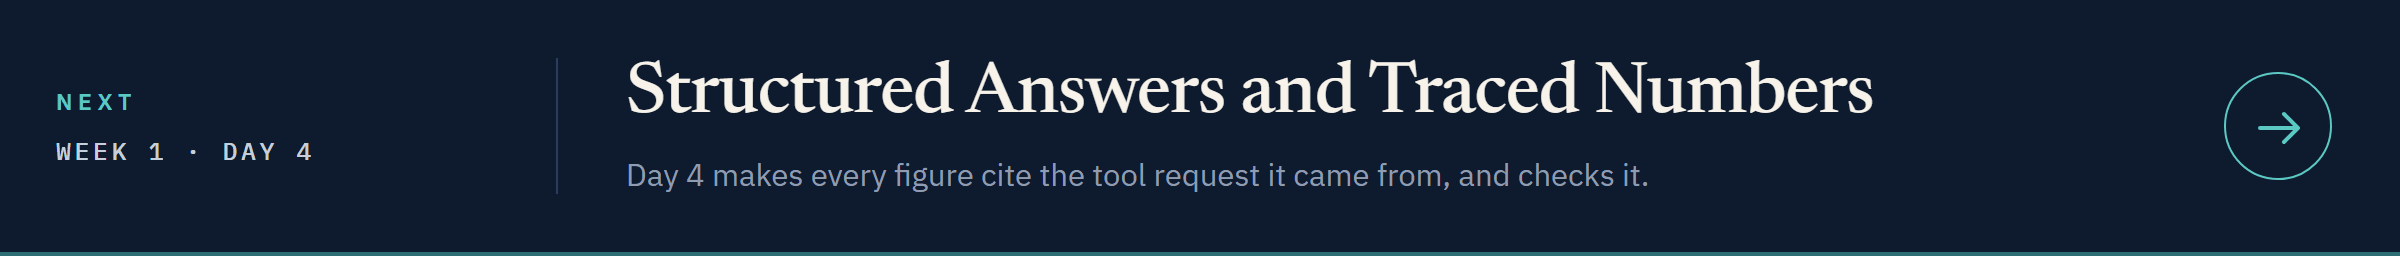](../day4/04_structured_answers_and_traced_numbers.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day4/04_structured_answers_and_traced_numbers.ipynb)